# Figure 2 — APA of in-situ-defined differential loops

Loop sets come from juicer `hiccupsdiff` on the two bulk in-situ Hi-C maps and never
see the single-cell data; the single-cell pseudobulk supplies only the piled-up signal.

**Run the pile-up first.** This notebook only plots a cached `.npz`. On a fresh run
submit `../../data_processing/bulk_others/04_hic_loops/05_apa_pileup_insitu.sbatch`
(step 05 of that chain); it writes `apa_insituHCD.npz` plus the APA scores and the
paired Mann–Whitney test in `apa_insituHCD_stats.tsv`. The `RECOMPUTE = True`
shortcut below recomputes in-process instead, but it imports that script under the
filename it carries in the working directory (`step08_apa_insitu_defined`).

Panel: `APA_2xN_insituHCD_diffloops_diffmap.pdf` — per loop, pixel by pixel,
log2(O/E in GM12878 ÷ O/E in IMR90), then the median across loops.


In [1]:
%matplotlib inline
import os
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

BASE = "/projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu"
sys.path.insert(0, BASE)

OUTDIR = f"{BASE}/data/diff/GM12878_IMR90_insitu_loops"
FIGDIR = f"{OUTDIR}/figures"

# ---- which in-situ differential loop definition to plot -------------------------
# "hiccupsdiff" -- juicer hiccupsdiff: tests contact frequency directly, with FDR.
#                  516 / 968 loops. A real test AND independent of the sc data.
# "setdiff"     -- scripts/diff_loops.py: presence/absence in the two HICCUPS call
#                  sets. 2,434 / 5,401 loops. Independent, but not a test.
LOOPSET = "hiccupsdiff"

_CFG = {
    "hiccupsdiff": ("apa_insituHCD.npz", "APA_2xN_insituHCD_diffloops",
                    "juicer hiccupsdiff (FDR-tested)"),
    "setdiff":     ("apa_insituDEF.npz", "APA_2xN_insituDEF_diffloops",
                    "HICCUPS set-difference"),
}
NPZ_NAME, FIG_BASE, LOOPSET_DESC = _CFG[LOOPSET]
NPZ = f"{FIGDIR}/{NPZ_NAME}"

celltypes = ["GM12878", "IMR90"]

res             = 25000
apa_flank_bp    = 200_000
apa_flank_bins  = apa_flank_bp // res          # 8
apa_window_size = 2 * apa_flank_bins + 1       # 17
BG_WIDTH        = max(1, min(5, apa_flank_bins))

# Colour limits for the min-max panel. The scHiCluster tutorial uses 0.2/0.8, but these
# data only span ~0.20-0.47, so 0.8 wastes more than half the colour range and every panel
# reads as pale yellow. 0.5 uses the full ramp. The cell below reports any clipping --
# hiccupsdiff clips nothing (max 0.474); setdiff peaks at 0.543 and would clip ~0.8% of
# pixels, so raise VMAX_MM to 0.55 if you switch LOOPSET.
VMIN_MM, VMAX_MM = 0.2, 0.5

# Per-panel score titles. False gives bare panels for a publication figure --
# the numbers are still printed as tables in section 3 and written to the
# stats .tsv in section 7.
SHOW_PANEL_SCORES = False

# Gap between panels, as a fraction of panel size. These were sized to fit the
# two-line score titles; with SHOW_PANEL_SCORES = False they can be much tighter.
# Raise them if you turn the titles back on.
PANEL_WSPACE, PANEL_HSPACE = 0.10, 0.10

# Arial + editable text in Illustrator, matching the rest of the figure set
mpl.rcParams["font.family"]     = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Liberation Sans", "DejaVu Sans"]
mpl.rcParams["pdf.fonttype"]    = 42
mpl.rcParams["ps.fonttype"]     = 42

print(f"LOOPSET = {LOOPSET}  ({LOOPSET_DESC})")
print(f"window {apa_window_size}x{apa_window_size} "
      f"(+/-{apa_flank_bp//1000} kb at {res//1000} kb), corner background {BG_WIDTH}x{BG_WIDTH}")

LOOPSET = hiccupsdiff  (juicer hiccupsdiff (FDR-tested))
window 17x17 (+/-200 kb at 25 kb), corner background 5x5


In [2]:
RECOMPUTE = False   # True -> redo the pile-up from the .Q.cool files (~45 s, 2 workers)

if RECOMPUTE:
    os.environ["APA_LOOPSET"] = LOOPSET   # step08 reads this at import time
    import cooler
    from concurrent.futures import ProcessPoolExecutor, as_completed
    import step08_apa_insitu_defined as s8

    chrom_sizes = cooler.read_chromsizes(s8.chrom_size_path, all_names=True)
    if not any(str(c).startswith("chr") for c in chrom_sizes.index):
        chrom_sizes.index = ["chr" + str(c) for c in chrom_sizes.index]
    chrom_index = list(chrom_sizes.index)          # all 22 autosomes
    print(f"chromosomes: {len(chrom_index)} ({chrom_index[0]}..{chrom_index[-1]})")

    loop_labels, loop_list = s8.load_loopsets()
    n_rows, n_cols = len(celltypes), len(loop_list)

    vis_all = np.full((n_rows, n_cols, apa_window_size, apa_window_size), np.nan)
    raw_all = np.full_like(vis_all, np.nan)
    cnt_all = np.zeros((n_rows, n_cols), dtype=np.int64)
    centres, wins_all = {}, {}

    with ProcessPoolExecutor(max_workers=2) as ex:
        futs = {ex.submit(s8.apa, ct, s8.indir, chrom_index, loop_list,
                          res, s8.dist, apa_flank_bins): i
                for i, ct in enumerate(celltypes)}
        for fut in as_completed(futs):
            i = futs[fut]
            v, r, c, ctr, wins = fut.result()
            vis_all[i], raw_all[i], cnt_all[i] = v, r, c
            centres[celltypes[i]] = ctr
            wins_all[celltypes[i]] = wins
            print(f"  {celltypes[i]} finished")

    diffmap = np.full((n_cols, apa_window_size, apa_window_size), np.nan)
    for j in range(n_cols):
        with np.errstate(divide="ignore", invalid="ignore"):
            lr = np.log2(wins_all["GM12878"][j] / wins_all["IMR90"][j])
        lr[~np.isfinite(lr)] = np.nan
        if np.any(np.isfinite(lr)):
            diffmap[j] = np.nanmedian(lr, axis=0)
else:
    z = np.load(NPZ, allow_pickle=False)
    vis_all = z["vis_all"]
    raw_all = z["raw_all"]
    cnt_all = z["cnt_all"]
    diffmap = z["diffmap"]
    loop_labels = [str(s) for s in z["loop_labels"]]
    n_rows, n_cols = vis_all.shape[0], vis_all.shape[1]
    centres = {ct: [z[f"centres_{ct}_{j}"] for j in range(n_cols)] for ct in celltypes}
    print(f"loaded {NPZ}")

print("\nwindows contributing to each panel:")
pd.DataFrame(cnt_all, index=celltypes, columns=loop_labels)

loaded /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/apa_insituHCD.npz

windows contributing to each panel:


,GM12878 specific loops,IMR90 specific loops
GM12878,287,666
IMR90,286,666


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_diffmap.png


saved: /projects/b1198/epifluidlab/yoshii/sc_nomehic_cellline/snakemake/APA/insitu/data/diff/GM12878_IMR90_insitu_loops/figures/APA_2xN_insituHCD_diffloops_diffmap.pdf


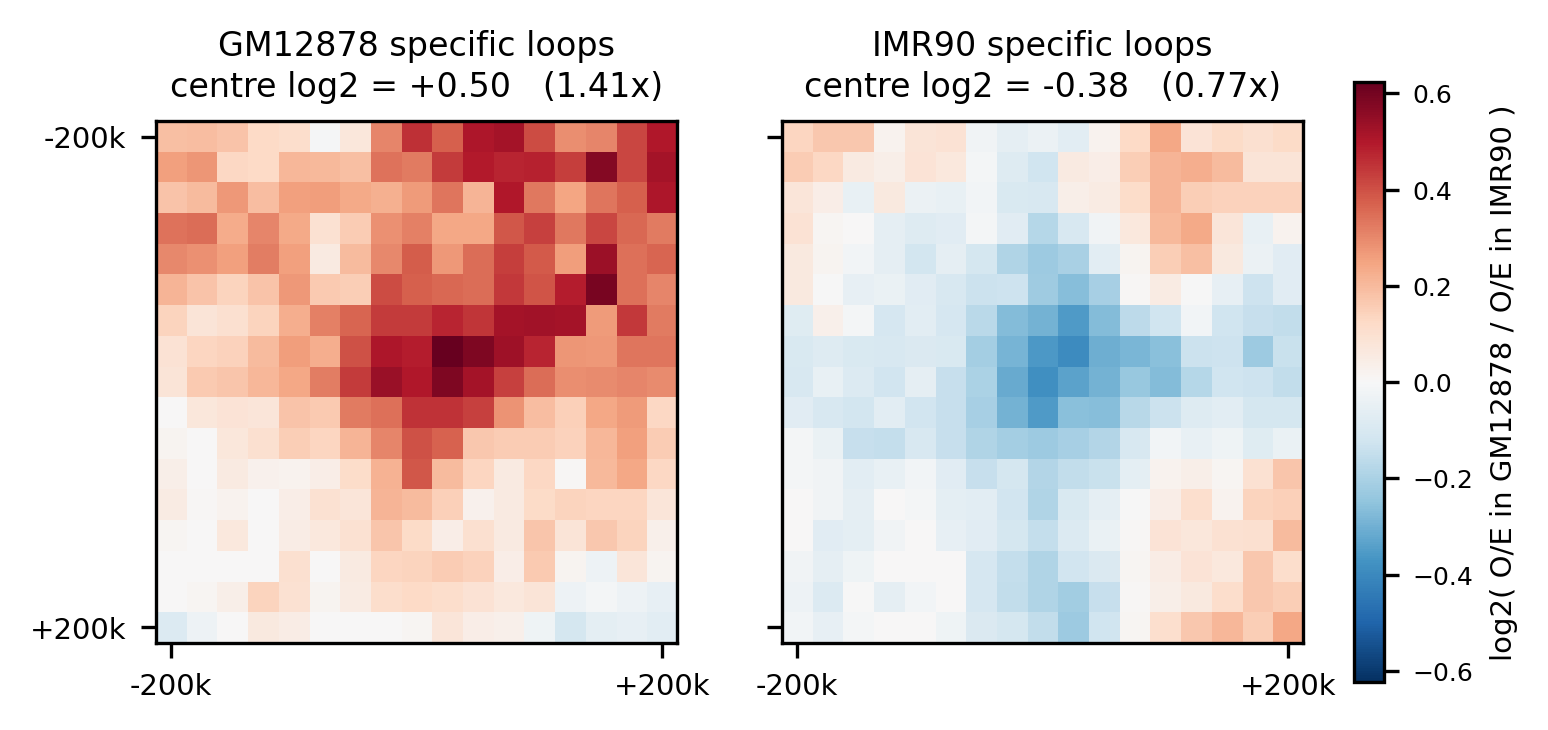


Sign check -- GM-specific should be positive, IMR-specific negative:
  GM12878 specific loops     centre log2 = +0.499   expected +, got +   OK
  IMR90 specific loops       centre log2 = -0.382   expected -, got -   OK


In [8]:
gm_i, imr_i = celltypes.index("GM12878"), celltypes.index("IMR90")

# Median over loops of the per-loop log2(GM window / IMR window) -- not
# log2(mean GM / mean IMR), which a few strong shared loops wash toward zero.
diff_maps = [diffmap[j] for j in range(n_cols)]

lim = min(float(np.nanmax(np.abs(diffmap[np.isfinite(diffmap)]))), 1.5)

fig, axes = plt.subplots(1, n_cols, figsize=(n_cols * 2.7, 2.6), dpi=300,
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes)
edge = apa_window_size - 1
lab = f"{apa_flank_bp // 1000}k"

for j, lb in enumerate(loop_labels):
    ax = axes[j]
    im = ax.imshow(diff_maps[j], cmap="RdBu_r", vmin=-lim, vmax=lim)
    c = diff_maps[j][apa_flank_bins, apa_flank_bins]
    ax.set_title(f"{lb}\ncentre log2 = {c:+.2f}   ({2 ** c:.2f}x)", fontsize=8,
                 linespacing=1.3)
    ax.set_xticks([0, edge]); ax.set_xticklabels([f"-{lab}", f"+{lab}"], fontsize=7)
    ax.set_yticks([0, edge]); ax.set_yticklabels([f"-{lab}", f"+{lab}"], fontsize=7)

cbar = fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.046, pad=0.04)
cbar.set_label("log2( O/E in GM12878 / O/E in IMR90 )", fontsize=7)
cbar.ax.tick_params(labelsize=6)

for ext in ("png", "pdf"):
    p = f"{FIGDIR}/{FIG_BASE}_diffmap.{ext}"
    fig.savefig(p, dpi=300, bbox_inches="tight", transparent=(ext == "pdf"))
    print("saved:", p)
plt.show()

print("\nSign check -- GM-specific should be positive, IMR-specific negative:")
for j, lb in enumerate(loop_labels):
    c = diff_maps[j][apa_flank_bins, apa_flank_bins]
    want = "+" if j == 0 else "-"
    got = "+" if c > 0 else "-"
    print(f"  {lb:<26s} centre log2 = {c:+.3f}   expected {want}, got {got}   "
          f"{'OK' if want == got else '*** UNEXPECTED ***'}")